In [1]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Đường dẫn thư mục hiện tại chứa notebook
data_path = os.getcwd()

# Lấy danh sách file CSV
csv_files = glob.glob(os.path.join(data_path, "*.csv"))

print("Số lượng file CSV:", len(csv_files))

dataframes = {}

for file in csv_files:
    name = os.path.basename(file)
    df = pd.read_csv(file)

    dataframes[name] = df

    print("\n" + "=" * 60)
    print("FILE:", name)
    print("Kích thước:", df.shape)
    display(df.head())

for name, df in dataframes.items():
    print("\nFILE:", name)
    print("Số dòng:", df.shape[0])
    print("Số cột:", df.shape[1])
    print("Số giá trị thiếu:", df.isnull().sum().sum())
    print("Số dòng trùng:", df.duplicated().sum())

Số lượng file CSV: 2

FILE: LSDS-7_Complete_Blood_Count_CBC.upload_SUBMITTED.csv
Kích thước: (553, 9)


,ANALYTE,VALUE,RANGE_MIN,RANGE_MAX,UNITS,TEST_TYPE,SUBJECT_ID,SEX,TEST_DATE
0,WHITE BLOOD CELL COUNT,5.40,3.8,10.8,Thousand/uL,CBC,C001,M,L-92
1,RED BLOOD CELL COUNT,4.58,4.2,5.8,Million/uL,CBC,C001,M,L-92
2,HEMOGLOBIN,14.10,13.2,17.1,g/dL,CBC,C001,M,L-92
3,HEMATOCRIT,42.50,38.5,50.0,%,CBC,C001,M,L-92
4,MCV,92.80,80.0,100.0,fL,CBC,C001,M,L-92



FILE: LSDS-7_Complete_Blood_Count_CBC_TRANSFORMED.csv
Kích thước: (28, 61)


,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,...,platelet_count_range_max_thousand_per_microliter,rdw_value_percent,rdw_range_min_percent,rdw_range_max_percent,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,...,400,12.6,11,15,4.69,4.2,5.8,7.0,3.8,10.8
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,...,400,12.6,11,15,4.85,4.2,5.8,5.5,3.8,10.8
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,...,400,13.0,11,15,4.58,4.2,5.8,5.4,3.8,10.8
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,...,400,12.5,11,15,4.84,4.2,5.8,5.0,3.8,10.8
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,...,400,12.8,11,15,4.66,4.2,5.8,4.9,3.8,10.8



FILE: LSDS-7_Complete_Blood_Count_CBC.upload_SUBMITTED.csv
Số dòng: 553
Số cột: 9
Số giá trị thiếu: 0
Số dòng trùng: 0

FILE: LSDS-7_Complete_Blood_Count_CBC_TRANSFORMED.csv
Số dòng: 28
Số cột: 61
Số giá trị thiếu: 21
Số dòng trùng: 0


In [3]:
# Lấy dữ liệu Transformed
transformed_name = [
    name for name in dataframes
    if "TRANSFORMED" in name.upper()
][0]

cbc_df = dataframes[transformed_name].copy()

# Kiểm tra thông tin
print("Kích thước dữ liệu:", cbc_df.shape)

print("\nThông tin dữ liệu:")
cbc_df.info()

print("\nDanh sách các cột:")
for col in cbc_df.columns:
    print(col)

Kích thước dữ liệu: (28, 61)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 61 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Sample Name                                               28 non-null     object 
 1   absolute_basophils_value_cells_per_microliter             28 non-null     int64  
 2   absolute_basophils_range_min_cells_per_microliter         28 non-null     int64  
 3   absolute_basophils_range_max_cells_per_microliter         28 non-null     int64  
 4   absolute_eosinophils_value_cells_per_microliter           28 non-null     int64  
 5   absolute_eosinophils_range_min_cells_per_microliter       28 non-null     int64  
 6   absolute_eosinophils_range_max_cells_per_microliter       28 non-null     int64  
 7   absolute_lymphocytes_value_cells_per_microliter           28

In [4]:
missing_values = cbc_df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_df = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(cbc_df) * 100
    )
})

missing_df = missing_df.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_df)

print("Tổng giá trị thiếu:", cbc_df.isnull().sum().sum())

,Missing_Count,Missing_Percentage
mchc_range_min_grams_per_deciliter,4,14.285714
mchc_range_max_grams_per_deciliter,4,14.285714
mchc_value_grams_per_deciliter,4,14.285714
mch_value_picogram,2,7.142857
mch_range_max_picogram,2,7.142857
mch_range_min_picogram,2,7.142857
mcv_value_femtoliter,1,3.571429
mcv_range_min_femtoliter,1,3.571429
mcv_range_max_femtoliter,1,3.571429


Tổng giá trị thiếu: 21


In [5]:
print("Số dòng trùng lặp:", cbc_df.duplicated().sum())

print(
    "Số Sample Name trùng:",
    cbc_df["Sample Name"].duplicated().sum()
)

print("Số mẫu:", cbc_df["Sample Name"].nunique())

Số dòng trùng lặp: 0
Số Sample Name trùng: 0
Số mẫu: 28


In [6]:
id_cols = ["Sample Name"]

value_cols = [
    col for col in cbc_df.columns
    if "_value_" in col.lower()
]

reference_cols = [
    col for col in cbc_df.columns
    if "_range_min_" in col.lower()
    or "_range_max_" in col.lower()
]

print("Số cột ID:", len(id_cols))
print("Số cột giá trị xét nghiệm:", len(value_cols))
print("Số cột khoảng tham chiếu:", len(reference_cols))

print("\nCác chỉ số CBC:")
for col in value_cols:
    print(col)

Số cột ID: 1
Số cột giá trị xét nghiệm: 20
Số cột khoảng tham chiếu: 40

Các chỉ số CBC:
absolute_basophils_value_cells_per_microliter
absolute_eosinophils_value_cells_per_microliter
absolute_lymphocytes_value_cells_per_microliter
absolute_monocytes_value_cells_per_microliter
absolute_neutrophils_value_cells_per_microliter
basophils_value_percent
eosinophils_value_percent
hematocrit_value_percent
hemoglobin_value_percent
lymphocytes_value_percent
mch_value_picogram
mchc_value_grams_per_deciliter
mcv_value_femtoliter
monocytes_value_percent
mpv_value_femtoliter
neutrophils_value_percent
platelet_count_value_thousand_per_microliter
rdw_value_percent
red_blood_cell_count_value_million_per_microliter
white_blood_cell_count_value_thousand_per_microliter


In [7]:
import re

def extract_info(sample):
    match = re.match(r"(C\d+)_whole-blood_([LR])([+-]\d+)_cbc",
                     sample.strip(), re.I)
    if match:
        return pd.Series([match.group(1), int(match.group(3))])
    return pd.Series([None, None])

temporal_df = cbc_df.copy()
temporal_df[["Subject", "Mission_Day"]] = (
    temporal_df["Sample Name"].apply(extract_info)
)

temporal_df = temporal_df.sort_values(
    ["Subject", "Mission_Day"]
)

display(temporal_df[["Sample Name", "Subject", "Mission_Day"]])

,Sample Name,Subject,Mission_Day
2,C001_whole-blood_L-92_cbc,C001,-92
1,C001_whole-blood_L-44_cbc,C001,-44
0,C001_whole-blood_L-3_cbc,C001,-3
3,C001_whole-blood_R+1_cbc,C001,1
5,C001_whole-blood_R+45_cbc,C001,45
6,C001_whole-blood_R+82_cbc,C001,82
4,C001_whole-blood_R+194_cbc,C001,194
9,C002_whole-blood_L-92_cbc,C002,-92
8,C002_whole-blood_L-44_cbc,C002,-44
7,C002_whole-blood_L-3_cbc,C002,-3


In [8]:
#Thống kê mô tả
display(temporal_df[value_cols].describe().T)
#Kiểm tra giá trị thiếu
display(
    temporal_df[value_cols].isnull().sum()
    .loc[lambda x: x > 0]
)

,count,mean,std,min,25%,50%,75%,max
absolute_basophils_value_cells_per_microliter,28.0,58.928571,25.191016,19.00,45.000,50.500,71.7500,125.00
absolute_eosinophils_value_cells_per_microliter,28.0,211.214286,103.151581,88.00,157.750,190.500,258.2500,614.00
absolute_lymphocytes_value_cells_per_microliter,28.0,2414.821429,982.981973,1540.00,1918.250,2163.000,2646.0000,6826.00
absolute_monocytes_value_cells_per_microliter,28.0,666.071429,341.168138,302.00,443.250,588.500,841.5000,1997.00
absolute_neutrophils_value_cells_per_microliter,28.0,3640.967857,1349.241691,10.10,2846.000,3658.500,4402.7500,6408.00
basophils_value_percent,28.0,0.821429,0.321290,0.30,0.575,0.800,1.0250,1.40
eosinophils_value_percent,28.0,2.892857,1.059675,0.90,2.075,2.750,3.7000,4.80
hematocrit_value_percent,28.0,43.014286,4.399387,34.70,40.625,42.950,46.4500,50.00
hemoglobin_value_percent,28.0,14.350000,1.685779,11.50,13.200,14.350,15.8750,17.00
lymphocytes_value_percent,28.0,32.903571,6.692643,20.80,28.375,32.150,37.8000,44.90


mch_value_picogram                2
mchc_value_grams_per_deciliter    4
mcv_value_femtoliter              1
dtype: int64

In [9]:
outliers = []

for col in value_cols:
    prefix = col.split("_value_")[0]

    min_col = next(c for c in reference_cols
                   if c.startswith(prefix + "_range_min_"))
    max_col = next(c for c in reference_cols
                   if c.startswith(prefix + "_range_max_"))

    mask = (
        temporal_df[col].notna()
        & temporal_df[min_col].notna()
        & temporal_df[max_col].notna()
    )

    for idx in temporal_df[mask].index:
        value = temporal_df.loc[idx, col]
        low = temporal_df.loc[idx, min_col]
        high = temporal_df.loc[idx, max_col]

        if value < low or value > high:
            outliers.append({
                "Feature": col,
                "Sample": temporal_df.loc[idx, "Sample Name"],
                "Value": value,
                "Status": "Low" if value < low else "High"
            })

outlier_df = pd.DataFrame(outliers)
display(outlier_df)
print("Tổng số giá trị ngoài khoảng:", len(outlier_df))

,Feature,Sample,Value,Status
0,absolute_eosinophils_value_cells_per_microliter,C003_whole-blood_L-92_cbc,614.00,High
1,absolute_lymphocytes_value_cells_per_microliter,C003_whole-blood_L-92_cbc,6826.00,High
2,absolute_monocytes_value_cells_per_microliter,C003_whole-blood_L-92_cbc,1997.00,High
3,absolute_monocytes_value_cells_per_microliter,C004_whole-blood_L-3_cbc,965.00,High
4,absolute_monocytes_value_cells_per_microliter,C004_whole-blood_R+1_cbc,1029.00,High
5,absolute_monocytes_value_cells_per_microliter,C004_whole-blood_R+194_cbc,988.00,High
6,absolute_neutrophils_value_cells_per_microliter,C003_whole-blood_L-92_cbc,10.10,Low
7,hematocrit_value_percent,C002_whole-blood_R+82_cbc,34.70,Low
8,hemoglobin_value_percent,C002_whole-blood_L-3_cbc,11.50,Low
9,hemoglobin_value_percent,C002_whole-blood_R+82_cbc,11.50,Low


Tổng số giá trị ngoài khoảng: 16


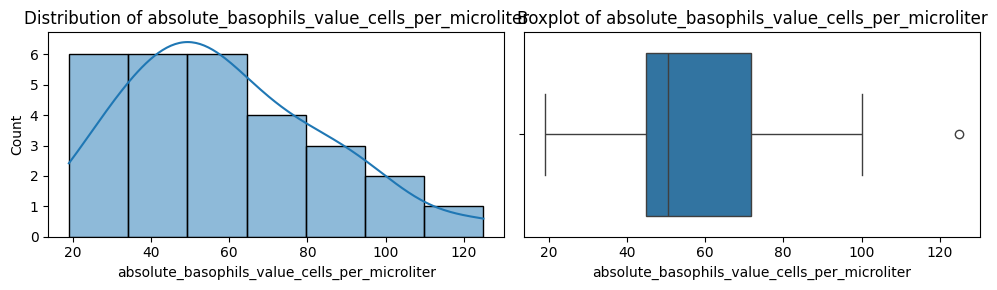

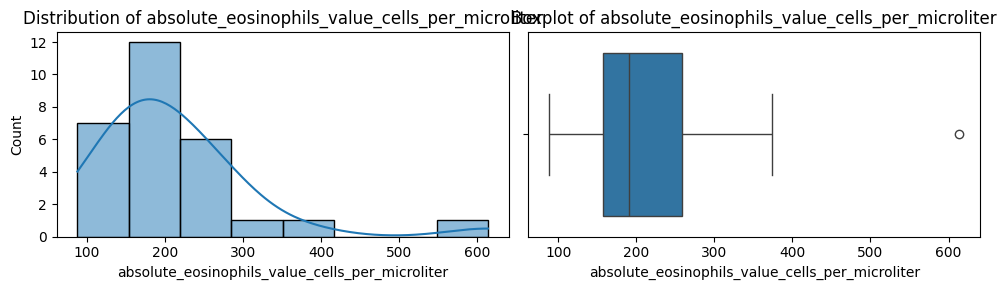

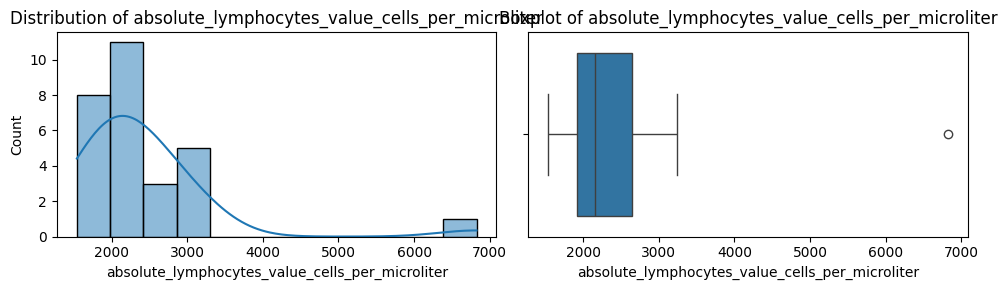

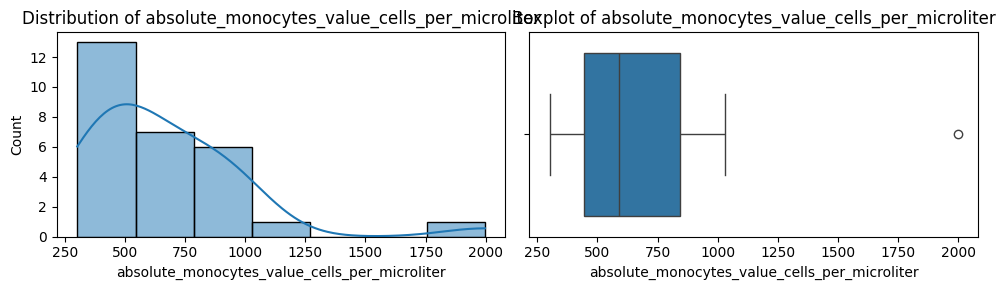

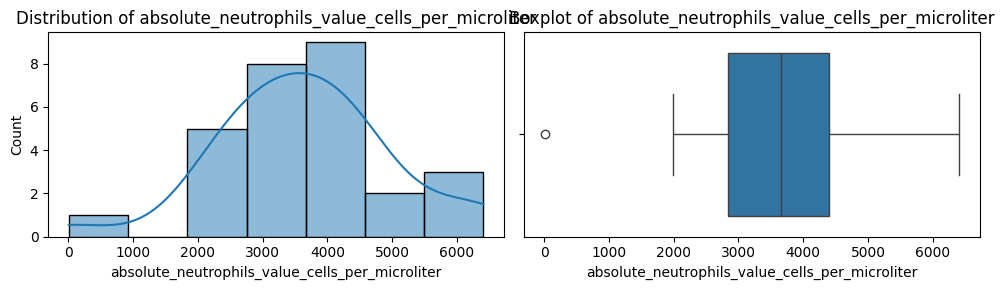

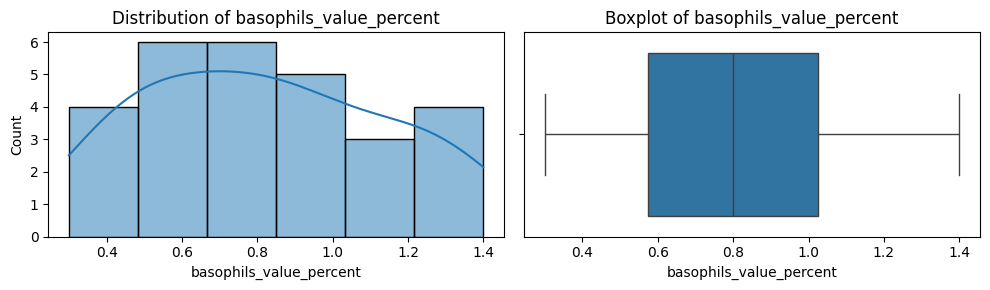

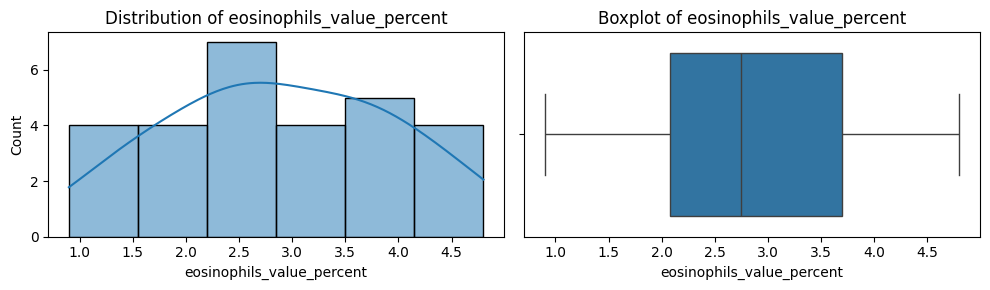

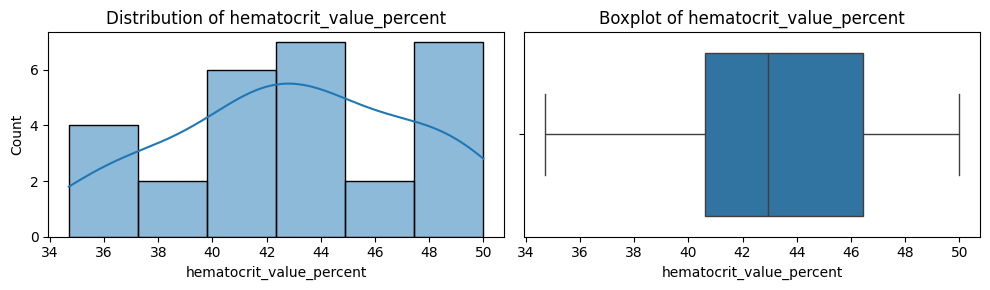

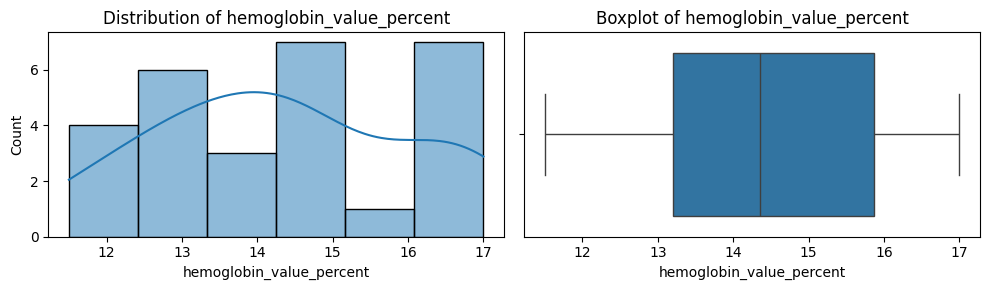

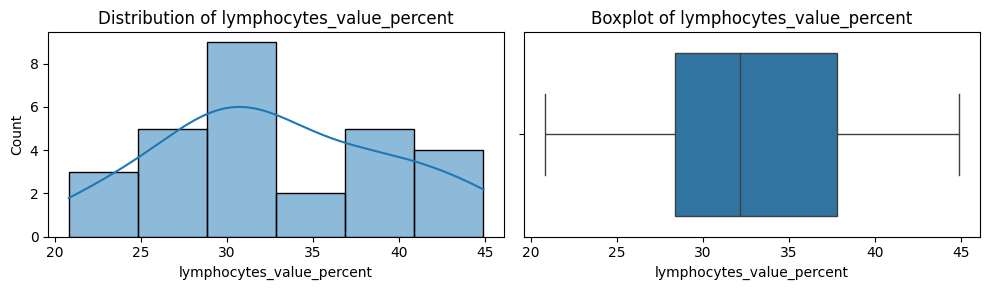

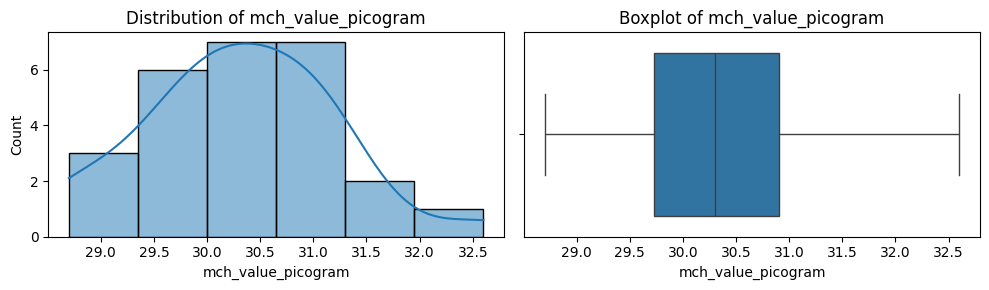

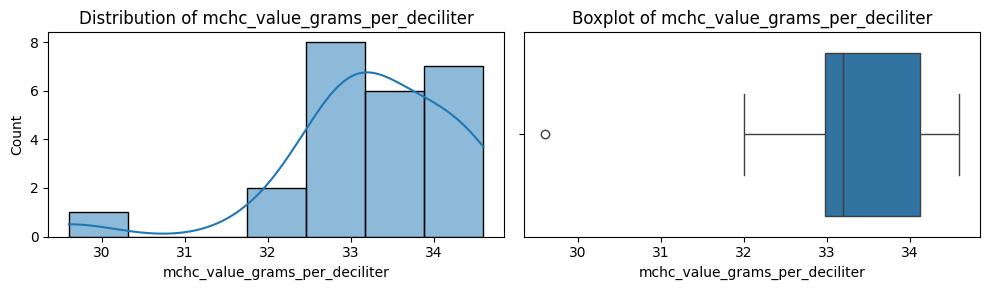

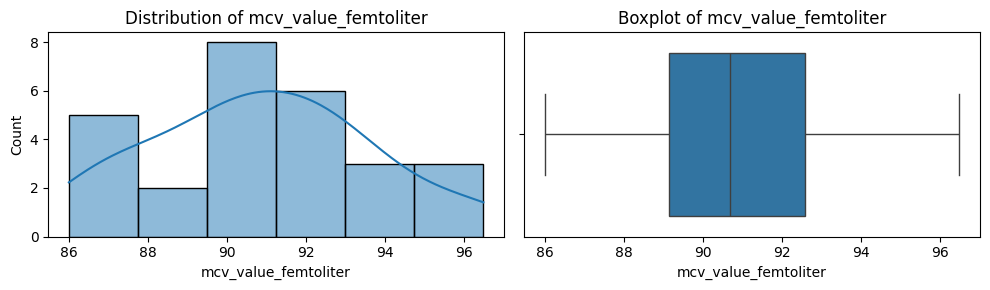

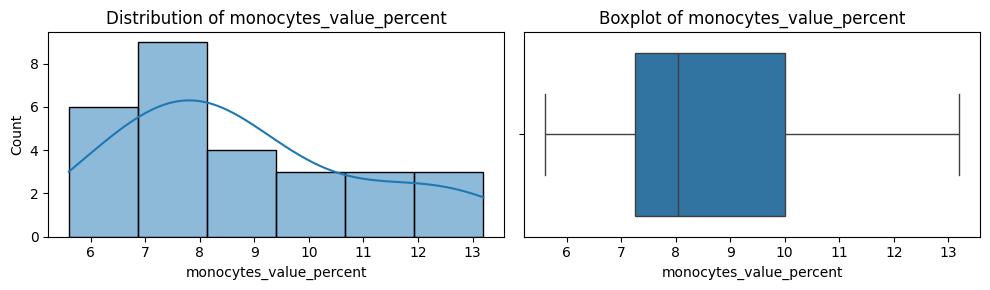

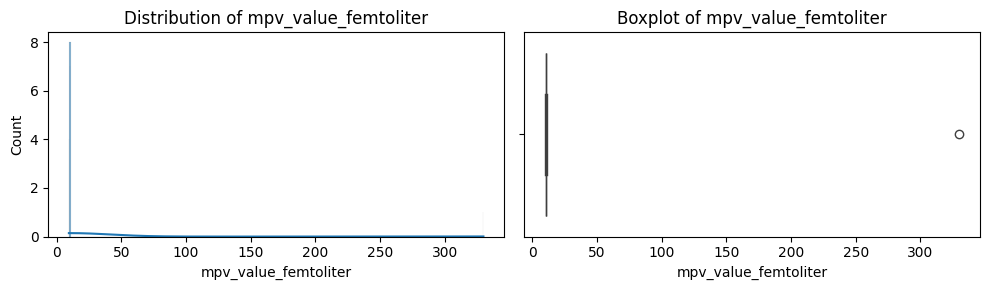

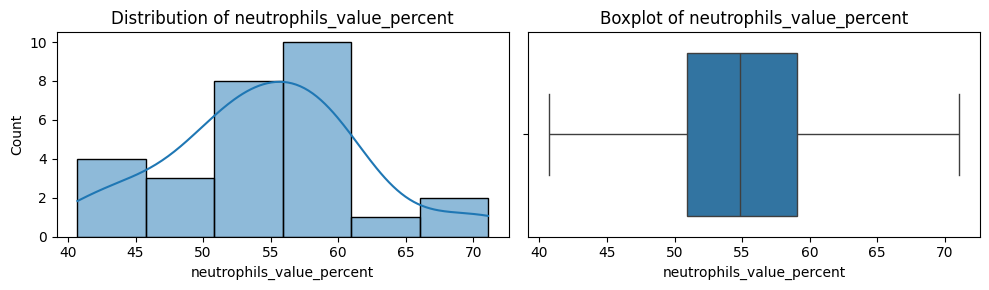

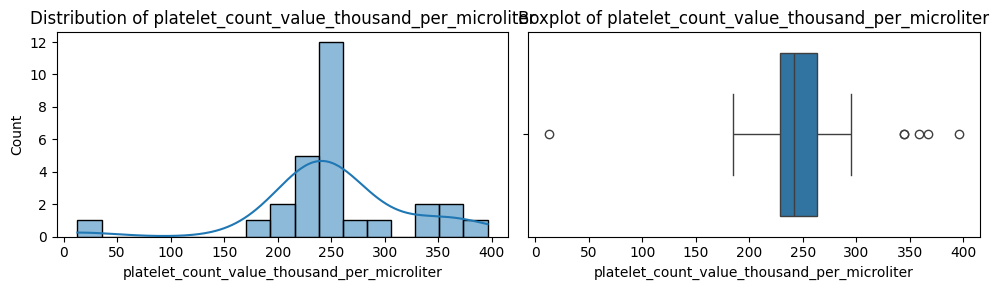

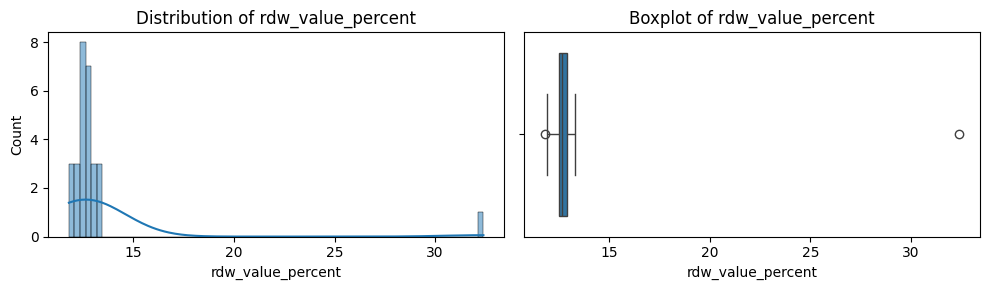

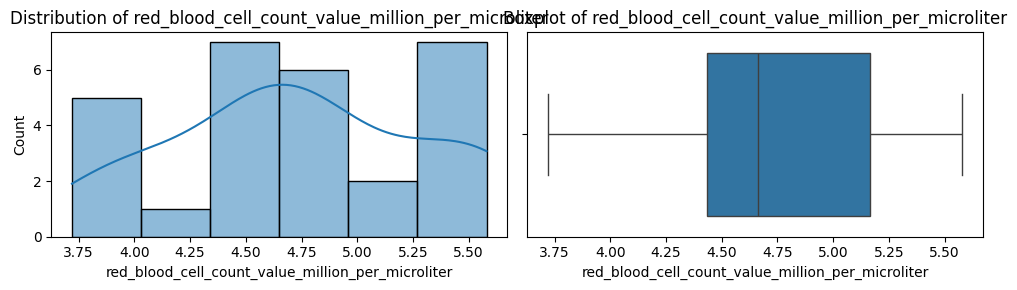

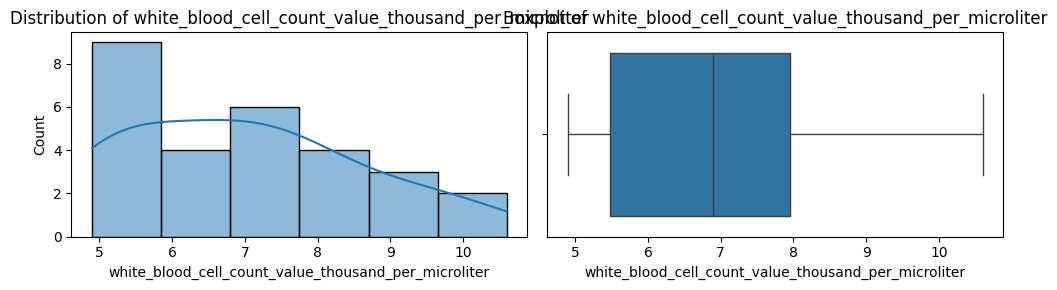

In [10]:
for col in value_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))

    sns.histplot(temporal_df[col], kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(x=temporal_df[col], ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

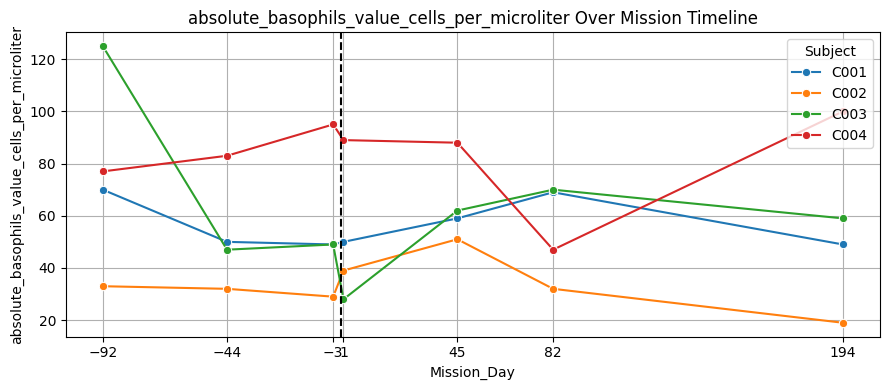

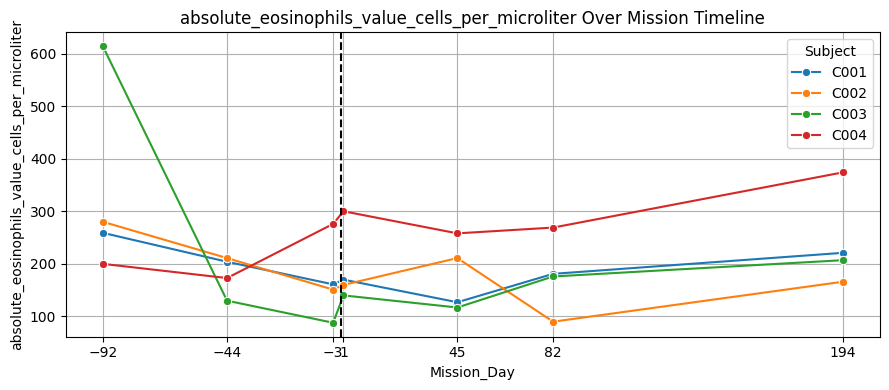

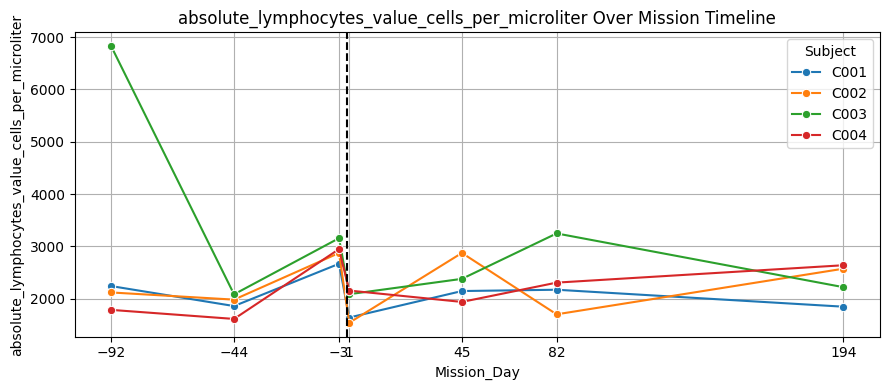

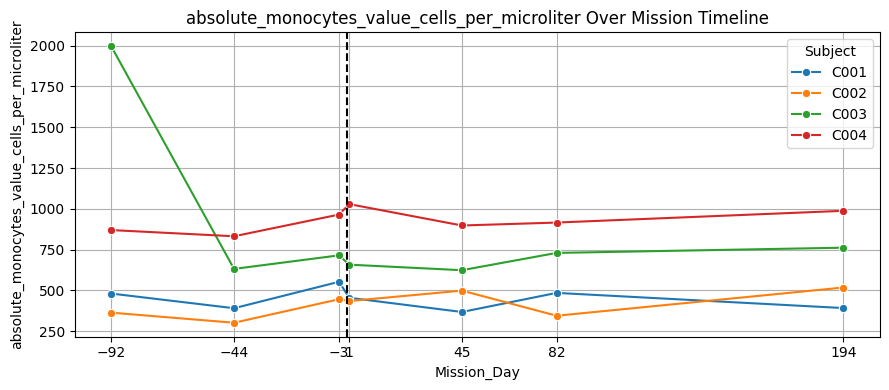

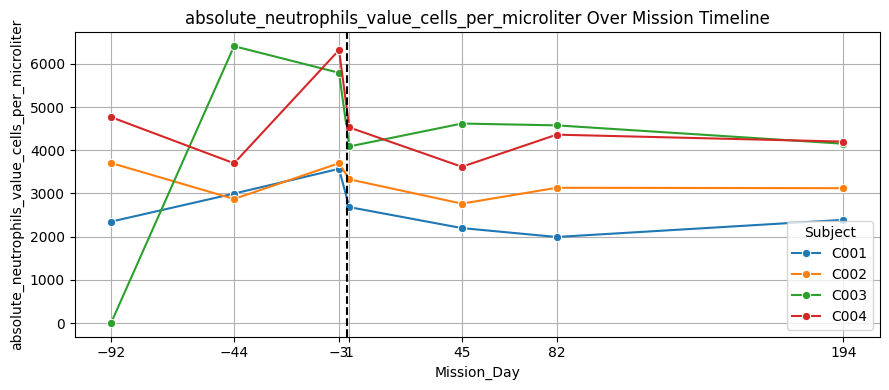

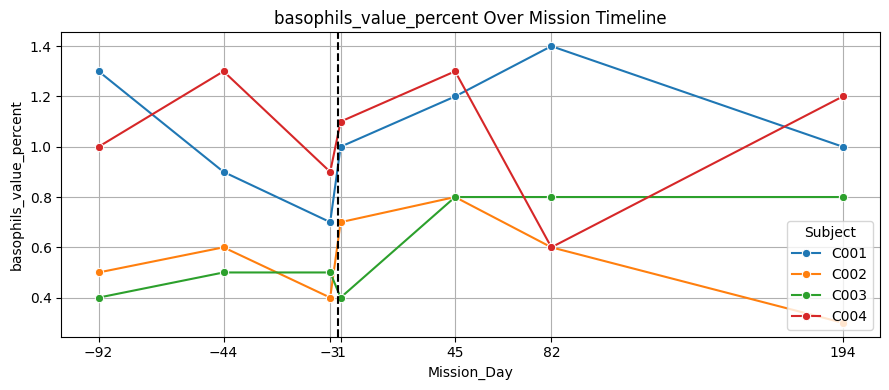

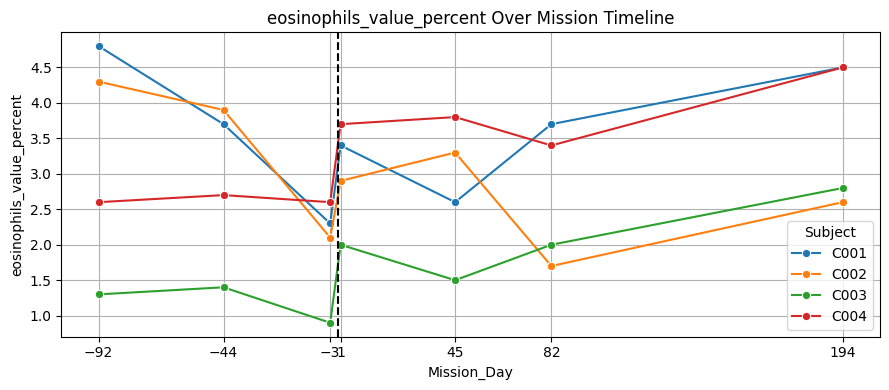

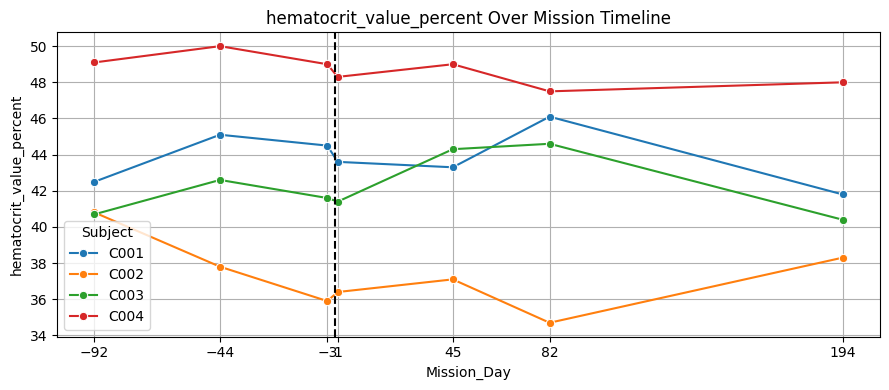

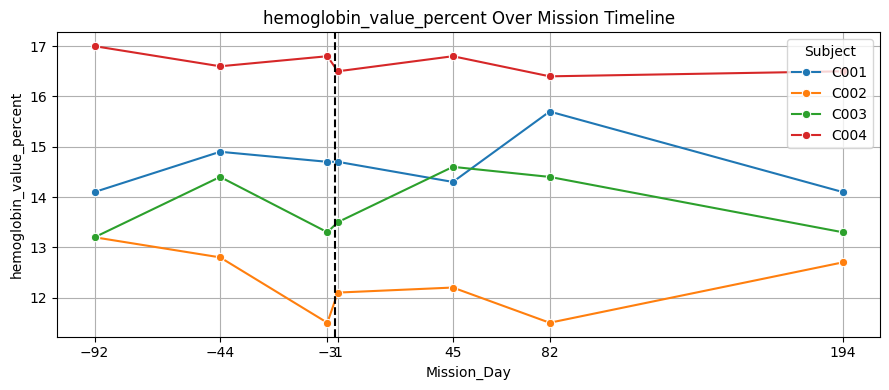

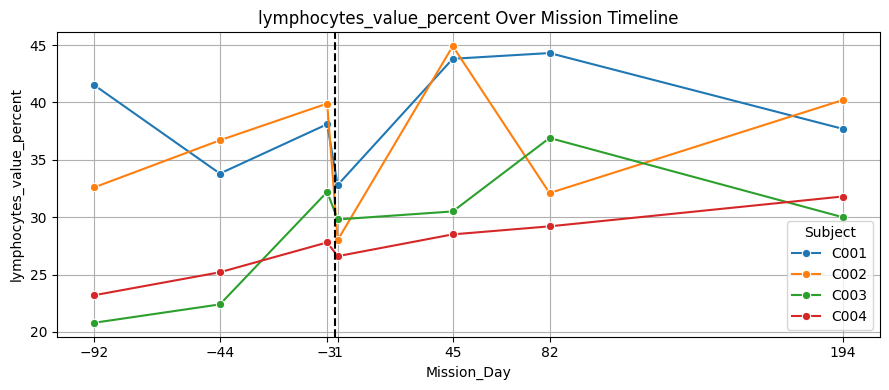

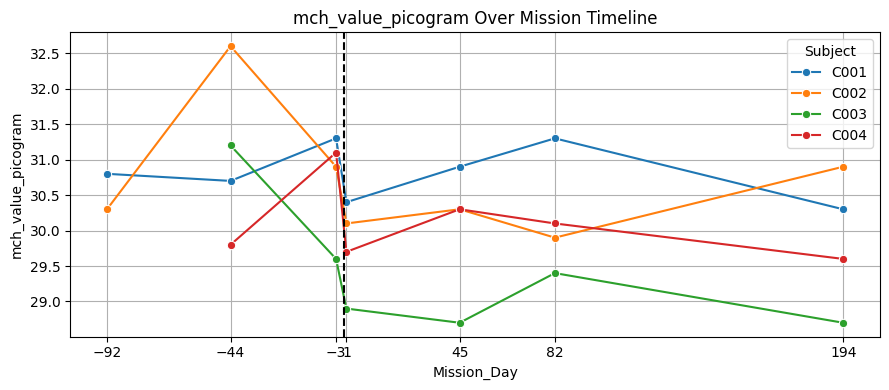

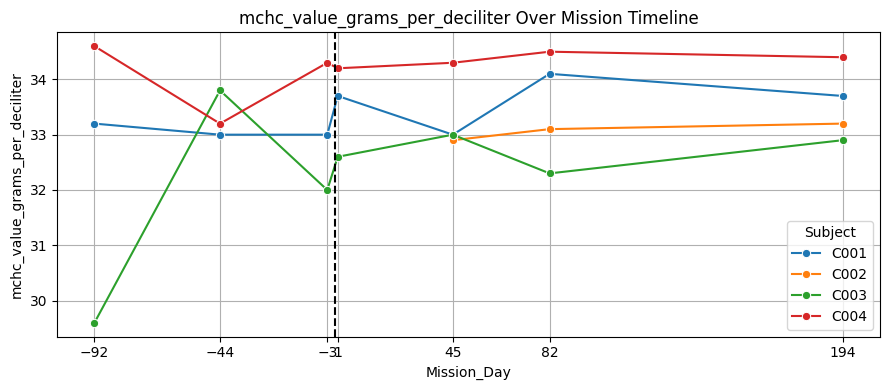

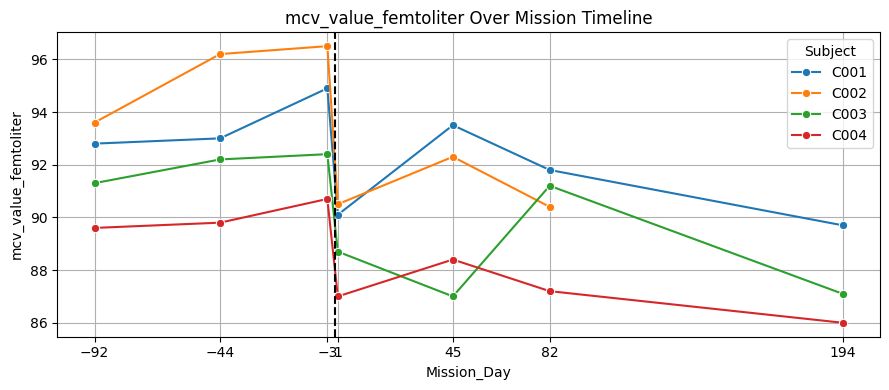

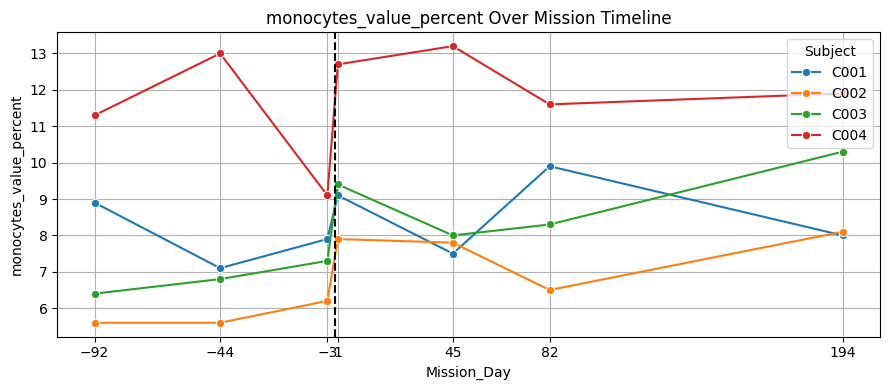

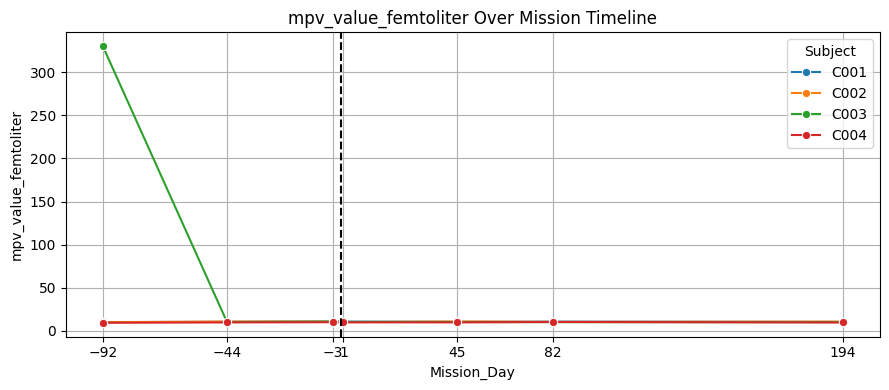

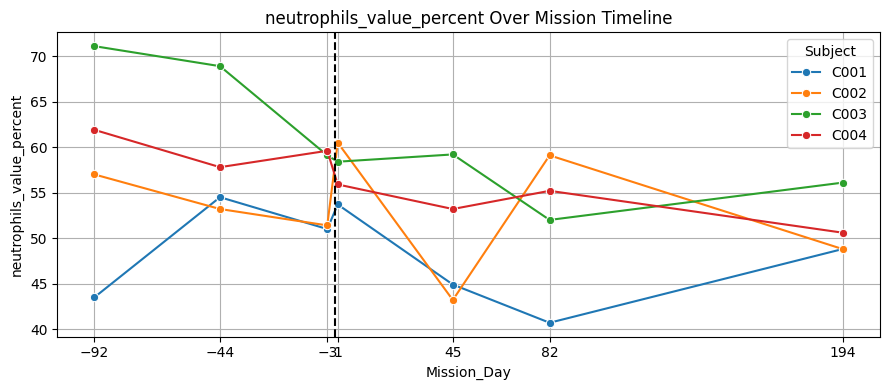

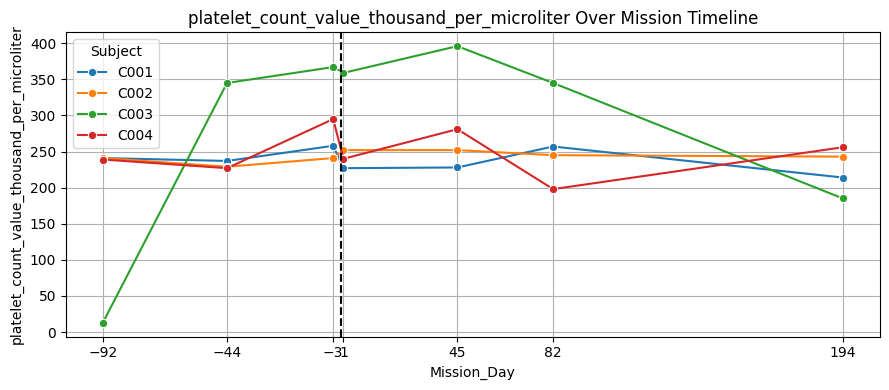

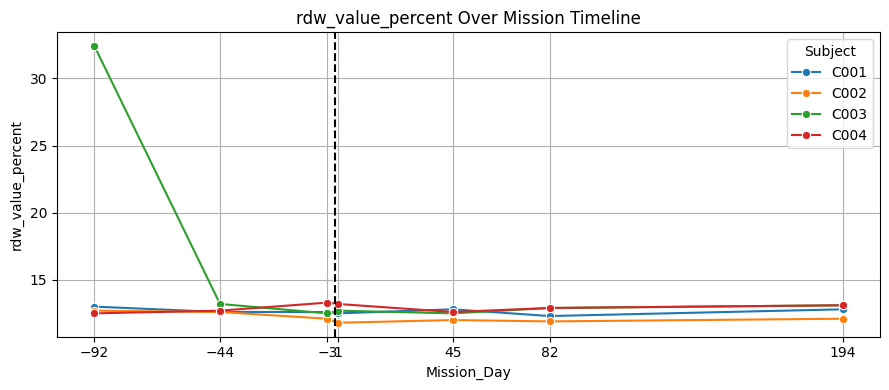

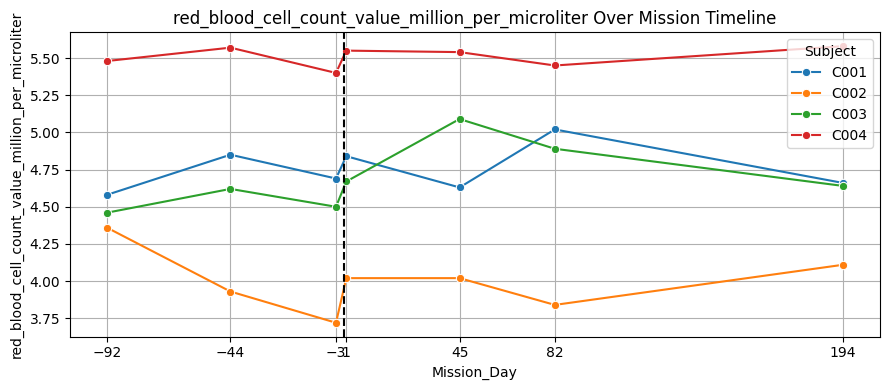

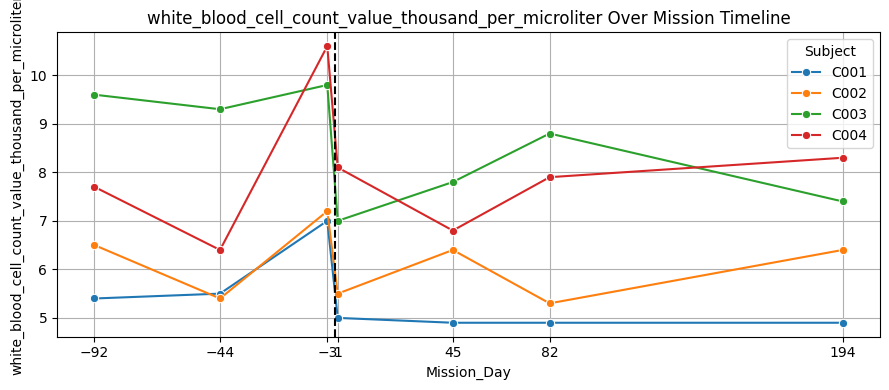

In [11]:
for col in value_cols:
    plt.figure(figsize=(9, 4))

    sns.lineplot(
        data=temporal_df,
        x="Mission_Day",
        y=col,
        hue="Subject",
        marker="o"
    )

    plt.title(f"{col} Over Mission Timeline")
    plt.xticks([-92, -44, -3, 1, 45, 82, 194])
    plt.axvline(0, linestyle="--", color="black")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

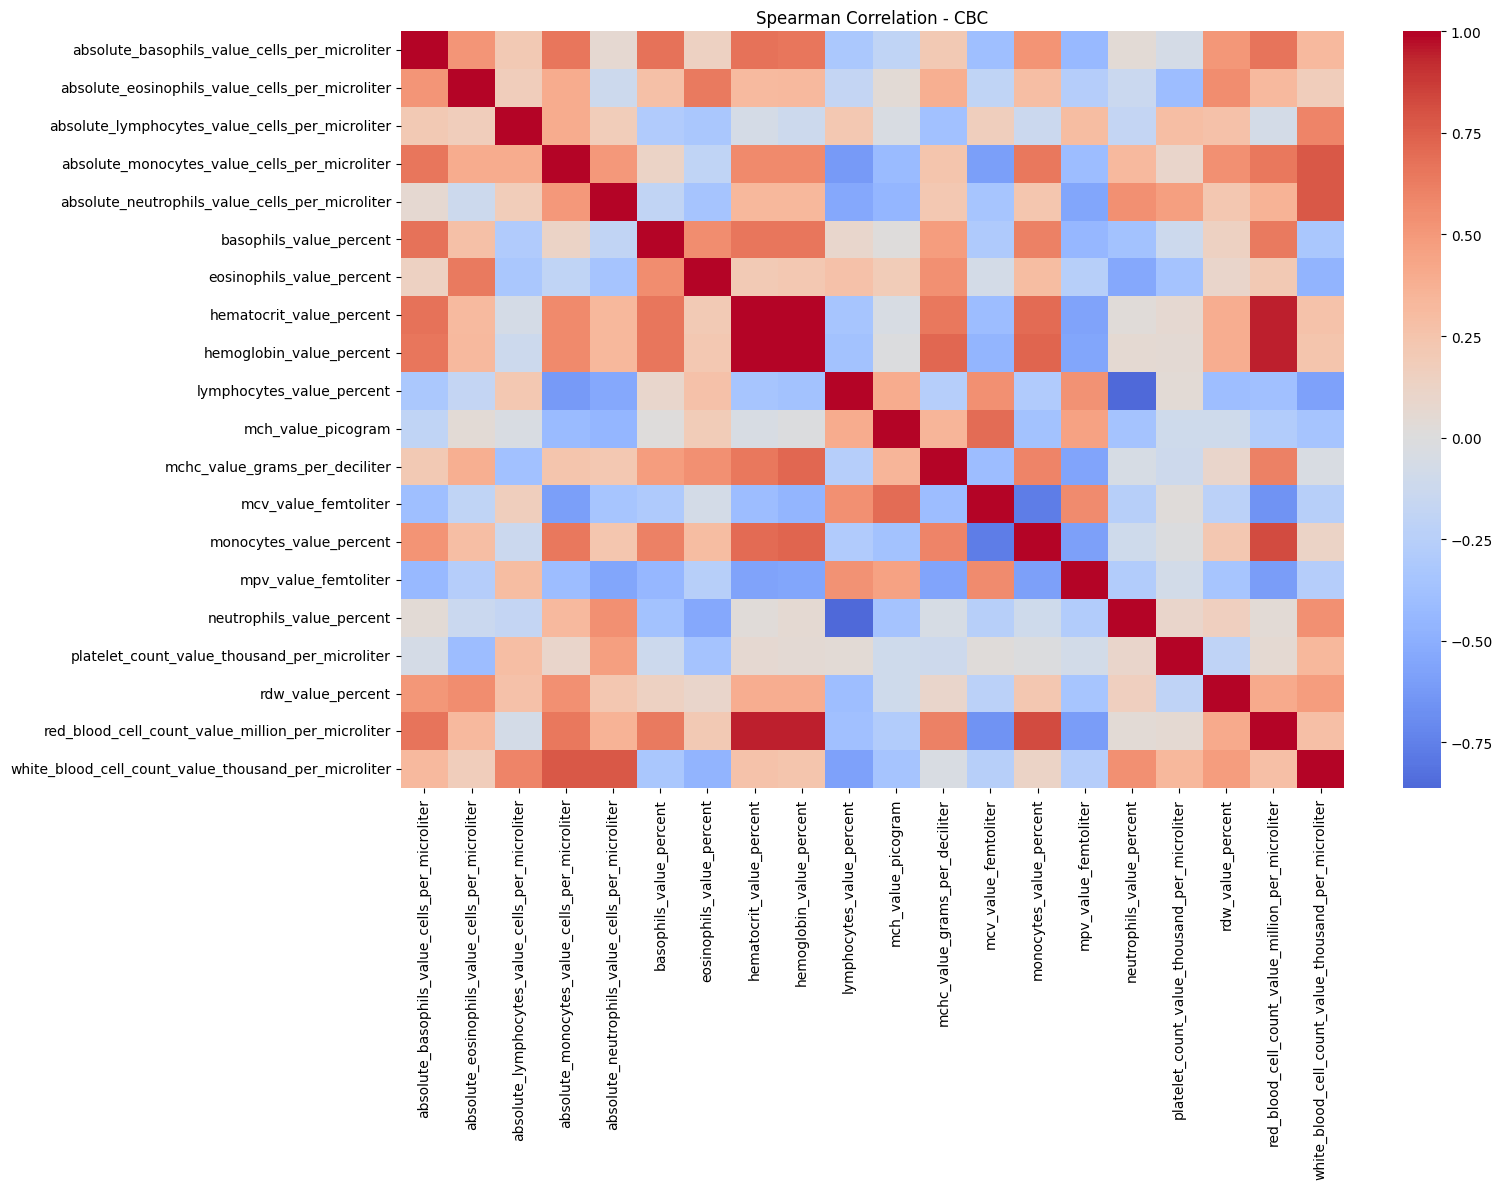

In [12]:
corr = temporal_df[value_cols].corr(method="spearman")

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Spearman Correlation - CBC")
plt.tight_layout()
plt.show()

In [13]:
iqr_outliers = []

for col in value_cols:
    Q1 = cbc_df[col].quantile(0.25)
    Q3 = cbc_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (cbc_df[col] < lower) |
        (cbc_df[col] > upper)
    ).sum()

    iqr_outliers.append({
        "Feature": col,
        "Outlier_Count": count,
        "Percentage": count / len(cbc_df) * 100
    })

iqr_df = pd.DataFrame(iqr_outliers)
iqr_df = iqr_df.sort_values(
    "Outlier_Count", ascending=False
)

display(iqr_df)
print("Tổng số outlier:", iqr_df["Outlier_Count"].sum())

,Feature,Outlier_Count,Percentage
16,platelet_count_value_thousand_per_microliter,6,21.428571
17,rdw_value_percent,2,7.142857
0,absolute_basophils_value_cells_per_microliter,1,3.571429
1,absolute_eosinophils_value_cells_per_microliter,1,3.571429
3,absolute_monocytes_value_cells_per_microliter,1,3.571429
2,absolute_lymphocytes_value_cells_per_microliter,1,3.571429
4,absolute_neutrophils_value_cells_per_microliter,1,3.571429
11,mchc_value_grams_per_deciliter,1,3.571429
14,mpv_value_femtoliter,1,3.571429
7,hematocrit_value_percent,0,0.000000


Tổng số outlier: 15


1. Nhận xét kết quả
- Platelet Count có nhiều outlier nhất: 6 (21,43%).
- RDW có 2 outlier (7,14%).
- 8 chỉ số còn lại có 1 outlier mỗi chỉ số.
- 10/20 chỉ số không có outlier.
- Tổng cộng 15 lần xuất hiện giá trị ngoại lệ trên các chỉ số.
Lưu ý: IQR chỉ đánh dấu ngoại lệ thống kê, không đồng nghĩa với bất thường sức khỏe. Chưa nên xóa các giá trị này.
2. Tổng kết EDA OSD-569
Hạng mục	Kết quả
Kích thước	28 mẫu × 61 cột
Đối tượng	4 người
Chỉ số CBC	20
Giá trị thiếu	21
Dữ liệu trùng	0
Ngoài khoảng tham chiếu	16
Outlier theo IQR	15